In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit.result import marginal_distribution
from qiskit.circuit.library import UGate
from math import pi
import random

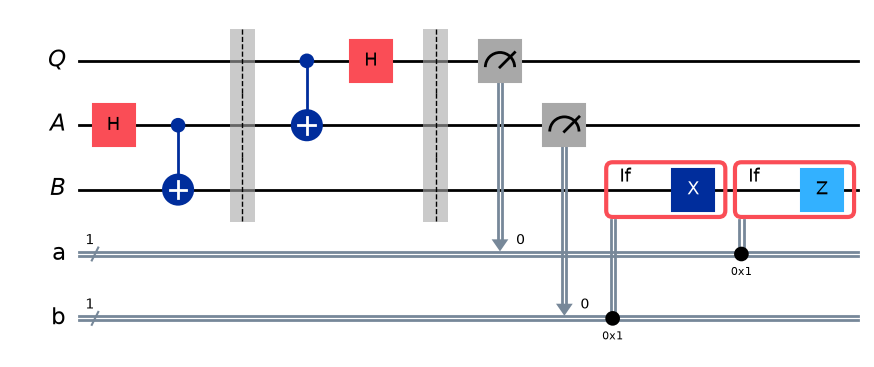

In [11]:
Q = QuantumRegister(1, "Q")
A = QuantumRegister(1, "A")
B = QuantumRegister(1, "B")
a = ClassicalRegister(1, "a")
b = ClassicalRegister(1, "b")

# Create circuit
teleportation = QuantumCircuit(Q, A, B, a, b)

# Create Bell pair
teleportation.h(A)
teleportation.cx(A, B)
teleportation.barrier()

# Change Basis
teleportation.cx(Q, A)
teleportation.h(Q)
teleportation.barrier()

# Measurement
teleportation.measure(Q, a)
teleportation.measure(A, b)

# Apply corrections
with teleportation.if_test((b, 1)):
    teleportation.x(B)
with teleportation.if_test((a, 1)):
    teleportation.z(B)

display(teleportation.draw(output="mpl", fold=-1))

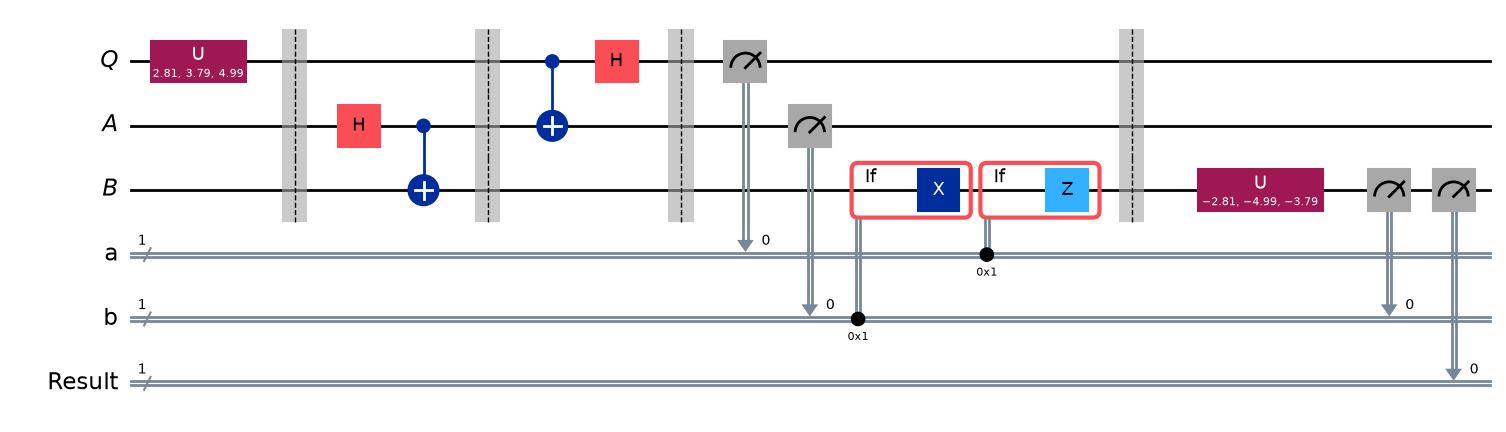

In [12]:
# Random gate for initialisation
random_gate = UGate(
    random.uniform(0, 2 * pi), 
    random.uniform(0, 2 * pi), 
    random.uniform(0, 2 * pi)
)

# Test circuit with random gate
test = QuantumCircuit(Q, A, B, a, b)
test.append(random_gate, [Q])
test.barrier()

# Append teleportation circuit
test = test.compose(teleportation)
test.barrier()

# Inverse of random gate for verification
test.append(random_gate.inverse(), [B])
result = test.measure(B, b)
test.add_register(ClassicalRegister(1, "Result"))
test.measure(B, test.clbits[-1])

display(test.draw(output="mpl", fold=-1))

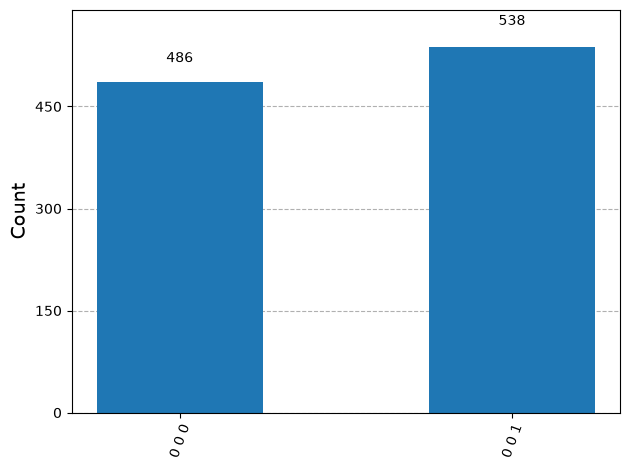

In [14]:
result = AerSimulator().run(test, shots=1024).result()
counts = result.get_counts()
display(plot_histogram(counts))

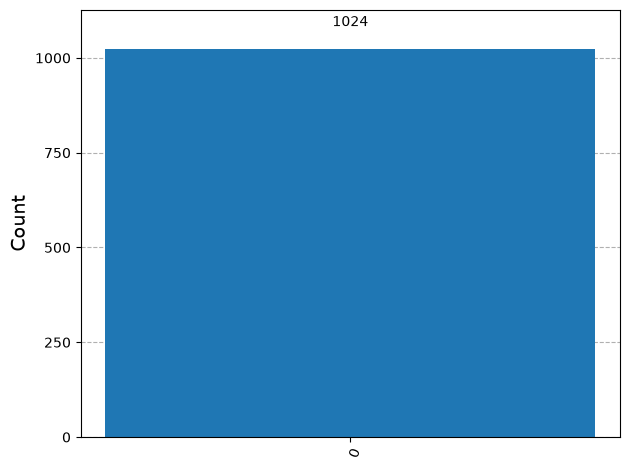

In [15]:
# Only results from test qubit
filtered_statistics = marginal_distribution(counts, [2])
display(plot_histogram(filtered_statistics))